157 2020-03-15 2023-03-12
date
2022-12-25     195.0
2023-01-01      94.0
2023-01-08      74.0
2023-01-15      84.0
2023-01-22    2488.0
2023-01-29      61.0
2023-02-05      78.0
2023-02-12     121.0
2023-02-19     129.0
2023-02-26     187.0
2023-03-05     169.0
2023-03-12     164.0
Freq: W-SUN, Name: cas_cumules, dtype: float64


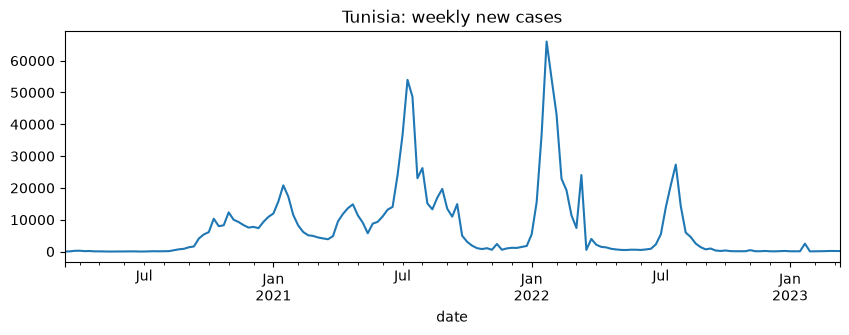

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/ml_base.csv", parse_dates=["date"])

def weekly_cases(country):
    s = (df[df["pays"] == country].set_index("date")["cas_cumules"]
           .resample("W").last().ffill().diff().clip(lower=0))
    return s.dropna()

tun = weekly_cases("Tunisia")
print(len(tun), tun.index.min().date(), tun.index.max().date())
print(tun.tail(12))
tun.plot(figsize=(10, 3), title="Tunisia: weekly new cases")
plt.show()

In [5]:
import numpy as np, logging
from prophet import Prophet
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)

def fit(series):
    d = series.reset_index(); d.columns = ["ds", "y"]
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    m.fit(d)
    return m

H = 12
rows = []
for c in ["2021-05-02", "2021-12-05", "2022-06-05", "2022-12-11"]:
    train = tun[tun.index <= c]
    test = tun[tun.index > c].iloc[:H]
    m = fit(train)
    pred = m.predict(pd.DataFrame({"ds": test.index}))["yhat"].clip(lower=0).values
    naive = np.full(len(test), train.iloc[-1])
    rows.append({"cutoff": c,
                 "MAE_prophet": np.abs(test.values - pred).mean(),
                 "MAE_naive": np.abs(test.values - naive).mean()})
res = pd.DataFrame(rows).round(0)
print(res)
print(res[["MAE_prophet", "MAE_naive"]].mean().round(0))

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.


       cutoff  MAE_prophet  MAE_naive
0  2021-05-02      12912.0    12230.0
1  2021-12-05      16130.0    22098.0
2  2022-06-05      12054.0     7848.0
3  2022-12-11      11946.0      247.0
MAE_prophet    13260.0
MAE_naive      10606.0
dtype: float64


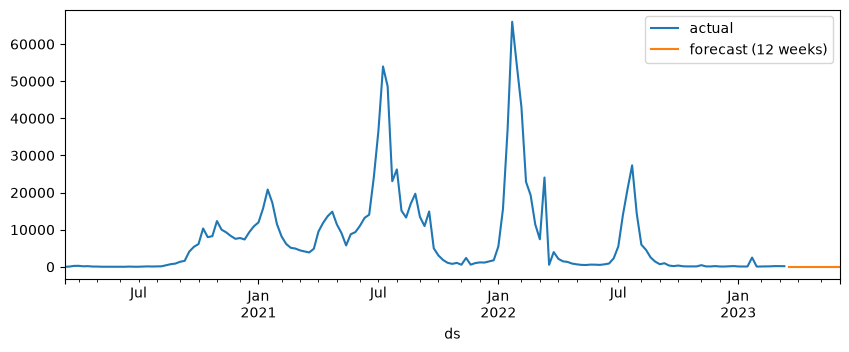

In [6]:
m = fit(tun)
fut = m.make_future_dataframe(periods=12, freq="W")
fc = m.predict(fut)[["ds", "yhat", "yhat_lower", "yhat_upper"]]
for col in ["yhat", "yhat_lower", "yhat_upper"]:
    fc[col] = fc[col].clip(lower=0)
fc.to_csv("../data/tunisia_forecast.csv", index=False)
ax = tun.plot(figsize=(10, 3.5), label="actual")
fc.set_index("ds")["yhat"].tail(12).plot(ax=ax, label="forecast (12 weeks)")
ax.legend(); plt.show()